# LAB 10 — QA fine-tuning and experiments

Maps to W10.pdf 14, 17–25. The notebook runs unit tests before opening the implementation gates. No Hugging Face QA pipeline is used.


In [1]:
from pathlib import Path
import subprocess, sys
roots = [Path.cwd(), Path.cwd()/"Lab10", Path("/content/NLP/Lab10"), Path("/content/drive/MyDrive/NLP/Lab10")]
LAB_DIR = next((p.resolve() for p in roots if (p/"qa_model.py").is_file()), None)
if LAB_DIR is None and Path("/content").exists():
    repo = Path("/content/NLP")
    if repo.exists():
        subprocess.run(["git", "-C", str(repo), "pull", "--ff-only", "origin", "main"], check=True)
    else:
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/NguyenDucThang-tb/NLP.git", str(repo)], check=True)
    LAB_DIR = repo/"Lab10"
if LAB_DIR is None or not (LAB_DIR/"qa_model.py").is_file():
    raise FileNotFoundError("Lab10/qa_model.py không có trong runtime. Push Lab10 lên GitHub rồi clone/pull repo.")
sys.path.insert(0, str(LAB_DIR))
print("LAB_DIR:", LAB_DIR)


LAB_DIR: /content/NLP/Lab10


## 1. Install, configure hardware, seed and fixed splits

In [2]:
import importlib.util
from importlib.metadata import PackageNotFoundError, version
from packaging.requirements import Requirement
from packaging.version import Version

requirements = [Requirement(line.strip()) for line in (LAB_DIR / "requirements.txt").read_text().splitlines()
                if line.strip() and not line.lstrip().startswith("#")]
missing_or_incompatible = []
for requirement in requirements:
    try:
        installed = Version(version(requirement.name))
    except PackageNotFoundError:
        missing_or_incompatible.append(str(requirement))
        continue
    if requirement.specifier and installed not in requirement.specifier:
        missing_or_incompatible.append(str(requirement))

if missing_or_incompatible:
    if importlib.util.find_spec("pip") is None:
        raise RuntimeError("pip is unavailable and dependencies are missing/incompatible: " + ", ".join(missing_or_incompatible))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(LAB_DIR / "requirements.txt")], check=True)
else:
    print("All requirements are already installed with compatible versions.")
if importlib.util.find_spec("torch") is None:
    raise RuntimeError("PyTorch is missing. Install a CPU/CUDA build appropriate for this runtime.")


All requirements are already installed with compatible versions.


In [3]:
import csv, json, math, re, time
from importlib.metadata import version
from dataclasses import replace
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from transformers import AutoModelForQuestionAnswering, DataCollatorWithPadding
from qa_model import *

MODE = "FULL"  # notebook này được cấu hình cho Colab T4; dùng QUICK để kiểm tra nhanh
GRAD_ACCUM_STEPS = 1
RUN_ID = f"{MODE.lower()}_seed42"  # giữ nguyên để tiếp tục checkpoint; đổi hậu tố cho lần chạy mới
BASE = replace(QAConfig(mode=MODE, gradient_accumulation_steps=GRAD_ACCUM_STEPS),
               epochs=1 if MODE == "QUICK" else 2)
CONTEXT_LENGTHS = (128, 256, 384)
COMMON_STRIDE = 64  # cùng stride cho cả ba độ dài
RUN_TRAINING = True  # unit tests bên dưới phải pass trước khi training bắt đầu
RESUME_EXISTING = True  # tự tiếp tục checkpoint đã lưu; context chưa có checkpoint sẽ train mới
EXPORT_TO_DRIVE = False
DRIVE_OUTPUT_DIR = Path("/content/drive/MyDrive/NLP/Lab10")
# Chỉ mở các cờ sau khi toàn bộ test suite chạy thành công và không có test bị skip.
verification = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", str(LAB_DIR / "tests"), "-v"],
    cwd=LAB_DIR, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
)
print(verification.stdout)
if verification.returncode != 0 or "skipped" in verification.stdout.lower():
    raise RuntimeError("QA tests failed or were skipped; training gates remain closed.")
ALIGNMENT_IMPLEMENTED = True
METRICS_IMPLEMENTED = True
ERROR_ANALYSIS_IMPLEMENTED = True
DEVICE = torch.device(get_device())
RUN_OUTPUT_DIR = LAB_DIR / "outputs" / RUN_ID
RUN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(RUN_OUTPUT_DIR / "checkpoints").mkdir(parents=True, exist_ok=True)
FORMAL_OUTPUT_DIR = LAB_DIR if MODE == "FULL" else RUN_OUTPUT_DIR
RESULTS_PATH = LAB_DIR / "results.csv" if MODE == "FULL" else RUN_OUTPUT_DIR / "results.csv"
seed_everything(BASE.seed)
if torch.cuda.is_available():
    gpu_props = torch.cuda.get_device_properties(0)
    accelerator = {"name": torch.cuda.get_device_name(0),
                   "vram_gib": round(gpu_props.total_memory / (1024 ** 3), 2)}
else:
    accelerator = {"name": "CPU", "vram_gib": None}
versions = {name: version(name) for name in ("torch", "transformers", "datasets", "numpy", "pandas", "matplotlib")}
print({"device": str(DEVICE), "cuda": torch.cuda.is_available(), "accelerator": accelerator,
       "versions": versions, "model": BASE.model_id, "seed": BASE.seed, "mode": MODE,
       "run_id": RUN_ID, "run_output_dir": str(RUN_OUTPUT_DIR),
       "sample_limits": BASE.sample_limits(), "batch_size": BASE.batch_size,
       "learning_rate": BASE.learning_rate, "epochs": BASE.epochs,
       "gradient_accumulation_steps": BASE.gradient_accumulation_steps,
       "fp16_enabled": bool(BASE.mixed_precision and torch.cuda.is_available()),
       "stride": COMMON_STRIDE})
if MODE == "FULL" and not torch.cuda.is_available():
    raise RuntimeError("FULL mode requires CUDA (Google Colab T4 recommended); use QUICK for CPU checks.")

# QUICK ghi riêng dưới outputs; chỉ FULL cập nhật results.csv chính thức.
def save_results(rows):
    upsert_results_csv(RESULTS_PATH, rows)


test_checkpoint_resume_requires_saved_trainer_state (test_qa_framework.TestArtifactUtilities.test_checkpoint_resume_requires_saved_trainer_state) ... ok
test_environment_report_works_without_cuda (test_qa_framework.TestArtifactUtilities.test_environment_report_works_without_cuda) ... ok
test_results_csv_upsert_keeps_other_experiments_and_replaces_same_key (test_qa_framework.TestArtifactUtilities.test_results_csv_upsert_keeps_other_experiments_and_replaces_same_key) ... ok
test_common_stride_is_valid_for_context_length_experiment (test_qa_framework.TestConfiguration.test_common_stride_is_valid_for_context_length_experiment) ... ok
test_default_configuration (test_qa_framework.TestConfiguration.test_default_configuration) ... ok
test_fixed_split_sizes_and_reproducibility (test_qa_framework.TestDataSplit.test_fixed_split_sizes_and_reproducibility) ... ok
test_split_title_validator_rejects_leakage (test_qa_framework.TestDataSplit.test_split_title_validator_rejects_leakage) ... ok
test_spli

In [4]:
dataset = load_squad(BASE.dataset_id)
splits = create_fixed_splits(dataset, BASE)
title_sets = {name: {str(row.get("title", "")) for row in rows} for name, rows in splits.items()}
validate_split_titles(splits)  # kiểm tra cả article title và sample ID giữa các split
assert all(not (title_sets[a] & title_sets[b]) for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")])
print("split sizes:", {name: len(rows) for name, rows in splits.items()})
print("article title counts:", {name: len(values) for name, values in title_sets.items()})

# Chỉ tính thống kê; không in lại review/example trước khi prediction.md hoàn thành.
inspection_rows = []
for split_name, rows in splits.items():
    question_lengths = np.array([len(str(row["question"]).split()) for row in rows])
    context_lengths = np.array([len(str(row["context"]).split()) for row in rows])
    valid_offsets = sum(example_answer_is_in_context(row) for row in rows)
    inspection_rows.append({"split": split_name, "samples": len(rows),
        "question_words_mean": float(question_lengths.mean()) if len(rows) else float("nan"),
        "context_words_median": float(np.median(context_lengths)) if len(rows) else float("nan"),
        "context_words_p95": float(np.percentile(context_lengths, 95)) if len(rows) else float("nan"),
        "answer_offset_matches": valid_offsets,
        "answer_offset_mismatches": len(rows) - valid_offsets})
inspection_table = pd.DataFrame(inspection_rows)
display(inspection_table)

output_dir = RUN_OUTPUT_DIR
output_dir.mkdir(parents=True, exist_ok=True)
inspection_table.to_csv(output_dir / "dataset_inspection.csv", index=False)
save_json(output_dir / "split_manifest.json", {
    "dataset": BASE.dataset_id, "seed": BASE.seed,
    "split_ids": {name: [row["id"] for row in rows] for name, rows in splits.items()},
    "split_titles": {name: sorted(values) for name, values in title_sets.items()},
})

prediction_path = LAB_DIR / "prediction.md"
if prediction_path.is_file():
    prediction_text = prediction_path.read_text(encoding="utf-8")
    PREDICTION_COMPLETED = not any(line.strip().upper().startswith("TODO:") for line in prediction_text.splitlines())
else:
    prediction_text = ""
    PREDICTION_COMPLETED = False
    print("Prediction gate closed: prediction.md is missing; the accompanying PDF is not treated as a completed Markdown submission.")
print("prediction completed:", PREDICTION_COMPLETED)

env = environment_report(BASE, str(DEVICE))
env["splits"] = {name: len(rows) for name, rows in splits.items()}
save_json(output_dir / "environment.json", env)
save_json(output_dir / "run_config.json", BASE.to_dict())


README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.5MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

split sizes: {'train': 10000, 'validation': 1000, 'test': 1000}
article title counts: {'train': 441, 'validation': 24, 'test': 24}


,split,samples,question_words_mean,context_words_median,context_words_p95,answer_offset_matches,answer_offset_mismatches
0,train,10000,10.0264,110.0,214.0,10000,0
1,validation,1000,10.3240,112.0,203.1,1000,0
2,test,1000,10.1540,110.0,226.0,1000,0


prediction completed: True


## 2. Tokenizer and feature contract

Training and validation features keep model labels, offsets, context sequence IDs and `overflow_to_sample_mapping` for loss and answer-coverage checks. Validation features additionally keep `example_id` for span decoding. Inference loaders select model inputs only, so labels and alignment metadata are not passed to the model. It must not drop examples silently.

In [5]:
TOKENIZER_AVAILABLE = False
try:
    tokenizer = build_tokenizer(BASE.model_id)
    TOKENIZER_AVAILABLE = True
    print("fast tokenizer:", tokenizer.is_fast, "model input names:", tokenizer.model_input_names)
    max_question_tokens = max(len(tokenizer(row["question"], add_special_tokens=False)["input_ids"])
                              for rows in splits.values() for row in rows)
    pair_special_tokens = tokenizer.num_special_tokens_to_add(pair=True)
    min_context_capacity = min(CONTEXT_LENGTHS) - max_question_tokens - pair_special_tokens
    print({"max_question_subwords": max_question_tokens,
           "min_context_capacity": min_context_capacity, "common_stride": COMMON_STRIDE})
    if min_context_capacity < 1:
        raise ValueError("At least one context token must fit after the question and pair special tokens.")
    if COMMON_STRIDE >= min_context_capacity:
        requested_stride = COMMON_STRIDE
        COMMON_STRIDE = min_context_capacity - 1
        print(f"Adjusted common stride from {requested_stride} to {COMMON_STRIDE} to fit the longest question.")
    if PREDICTION_COMPLETED:
        print("sample question:", splits["train"][0]["question"])
        print("sample gold metadata:", splits["train"][0]["answers"])
    else:
        print("Prediction gate is closed; sample answer metadata is not displayed.")
except OSError as error:
    tokenizer = None
    print("NOT_RUN: pretrained tokenizer unavailable:", str(error).splitlines()[0])


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

fast tokenizer: True model input names: ['input_ids', 'token_type_ids', 'attention_mask']
{'max_question_subwords': 40, 'min_context_capacity': 85, 'common_stride': 64}
sample question: What poet wrote a long poem describing Roman religious holidays?
sample gold metadata: {'text': ['Ovid'], 'answer_start': [346]}


## QA head shape smoke check

Optional: loads the pretrained encoder and displays start/end logit shapes. This is an infrastructure check only, not fine-tuning or an experiment result.

In [6]:
RUN_MODEL_FORWARD_SMOKE = False
if RUN_MODEL_FORWARD_SMOKE:
    smoke_model = build_qa_model(BASE.model_id).to(DEVICE)
    batch = tokenizer(splits["train"][0]["question"], splits["train"][0]["context"],
                      truncation="only_second", max_length=64, return_tensors="pt")
    batch = {key:value.to(DEVICE) for key,value in batch.items() if key in tokenizer.model_input_names}
    with torch.no_grad():
        output = smoke_model(**batch)
    print("input_ids:",tuple(batch["input_ids"].shape))
    print("start_logits:",tuple(output.start_logits.shape))
    print("end_logits:",tuple(output.end_logits.shape))
    del smoke_model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    print("SKIPPED: set RUN_MODEL_FORWARD_SMOKE=True to load pretrained weights and inspect shapes")


SKIPPED: set RUN_MODEL_FORWARD_SMOKE=True to load pretrained weights and inspect shapes


## 3. Baseline — keyword overlap (mục 21)

In [7]:
# Baseline output is behind the prediction gate to avoid seeing results first.
if PREDICTION_COMPLETED:
    baseline_sample = splits["test"][0]
    baseline_candidate = keyword_overlap_baseline(baseline_sample["question"], baseline_sample["context"])
    print("question:", baseline_sample["question"])
    print("candidate span:", baseline_candidate)
    assert baseline_sample["context"][baseline_candidate["start_char"]:baseline_candidate["end_char"]] == baseline_candidate["answer"]
else:
    print("NOT_RUN: finish prediction.md before inspecting baseline predictions.")


question: What do supporters of Islamism believe their views reflect?
candidate span: {'answer': 'Islamism is a controversial concept not just because it posits a political role for Islam but also because its supporters believe their views merely reflect Islam, while the contrary idea that Islam is, or can be, apolitical is an error.', 'start_char': 0, 'end_char': 237, 'overlap_score': 1.0}


## 4. Model loaders and validation helper

Data collator receives only model fields/labels; feature metadata stays aligned in a parallel list.

In [8]:
def model_rows(features, tokenizer, labels=True):
    keys = set(tokenizer.model_input_names)
    if labels:
        keys |= {"start_positions", "end_positions"}
    return [{key: row[key] for key in keys if key in row} for row in features]

def make_loader(features, tokenizer, batch_size, shuffle=False, labels=True, seed=42):
    rows = model_rows(features, tokenizer, labels)
    collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(rows, batch_size=batch_size, shuffle=shuffle, collate_fn=collator,
                      generator=generator, pin_memory=torch.cuda.is_available())

def collect_logits(model, features, tokenizer, batch_size):
    loader = make_loader(features, tokenizer, batch_size, labels=False)
    model.eval(); starts, ends = [], []
    with torch.no_grad():
        for batch in loader:
            out = forward_qa_batch(model, batch, DEVICE)
            for row_index in range(len(batch["input_ids"])):
                size = int(batch["attention_mask"][row_index].sum())
                starts.append(out.start_logits[row_index, :size].detach().cpu().numpy())
                ends.append(out.end_logits[row_index, :size].detach().cpu().numpy())
    return starts, ends

def score_partition(model, examples, features, tokenizer, batch_size):
    start_logits, end_logits = collect_logits(model, features, tokenizer, batch_size)
    predictions = decode_qa_predictions(examples, features, start_logits, end_logits, BASE.max_answer_length)
    references = [{"id": row["id"], "answers": row["answers"]} for row in examples]
    return evaluate_predictions(predictions, references), predictions


def calculate_answer_coverage(examples, features):
    # Đếm mỗi example một lần dù có nhiều sliding windows.
    covered = set()
    for feature in features:
        source_index = feature.get("overflow_to_sample_mapping")
        if source_index is None:
            raise KeyError("Features must keep overflow_to_sample_mapping for coverage calculation")
        source_index = int(source_index)
        if window_answer_coverage(examples[source_index], feature):
            covered.add(source_index)
    return len(covered) / max(len(examples), 1)


## 5. Training gate

Prediction must be complete. Cell 4 runs the full test suite and opens the algorithm flags only if all tests pass with zero skips. Set `RUN_TRAINING=True` only when ready to start the selected QUICK or FULL run.


In [9]:
if not PREDICTION_COMPLETED:
    print("NOT_RUN: complete prediction.md before running experiments")
elif not TOKENIZER_AVAILABLE:
    print("NOT_RUN: pretrained tokenizer is unavailable")
elif not ALIGNMENT_IMPLEMENTED or not METRICS_IMPLEMENTED:
    print("NOT_RUN: complete student alignment/decoding/metric TODOs first")
elif not RUN_TRAINING:
    print("NOT_RUN: set RUN_TRAINING=True after selecting QUICK or FULL")
else:
    print("Gates passed")


Gates passed


## Experiment 1 — Context Length (W10 mục 14)

So sánh max_length 128, 256, 384; mỗi setting khởi tạo riêng từ cùng pretrained checkpoint và cùng cấu hình còn lại. Validation F1 chọn checkpoint; held-out partition chỉ dùng báo cáo kết quả.

## Experiment 2 — Pretrained QA Model (W10 mục 17)

Tái sử dụng lần fine-tuning max_length=384 ở Experiment 1 khi cấu hình trùng hoàn toàn. Loss theo epoch được ghi vào training history.


In [10]:
trained_runs = {}
result_rows = []
history_rows = []

def run_length(max_length):
    cfg = replace(BASE, max_length=max_length, stride=COMMON_STRIDE)
    cfg.validate(); seed_everything(cfg.seed)
    train_features = prepare_train_features(tokenizer, splits["train"], cfg.max_length, cfg.stride)
    val_features = prepare_validation_features(tokenizer, splits["validation"], cfg.max_length, cfg.stride)
    test_features = prepare_validation_features(tokenizer, splits["test"], cfg.max_length, cfg.stride)
    train_loader = make_loader(train_features, tokenizer, cfg.batch_size, shuffle=True, seed=cfg.seed)
    val_loader = make_loader(val_features, tokenizer, cfg.batch_size, shuffle=False, seed=cfg.seed)
    model = build_qa_model(cfg.model_id).to(DEVICE)  # khởi tạo độc lập từ cùng pretrained checkpoint
    checkpoint = RUN_OUTPUT_DIR / "checkpoints" / f"ctx{max_length}_seed{cfg.seed}"
    if checkpoint.exists() and not RESUME_EXISTING:
        raise FileExistsError(f"Checkpoint exists: {checkpoint}. Set RESUME_EXISTING=True to resume, or choose a new run name.")
    resume_path = checkpoint_resume_path(checkpoint, RESUME_EXISTING)
    if RESUME_EXISTING and checkpoint.exists() and resume_path is None:
        print(f"No trainer state in {checkpoint}; starting this context length from pretrained weights.")
    validate = lambda current: score_partition(current, splits["validation"], val_features, tokenizer, cfg.batch_size)[0]
    save_json(RUN_OUTPUT_DIR / f"run_config_ctx{max_length}.json", cfg.to_dict())
    best_model, history, training_seconds = train_with_validation(
        model, train_loader, val_loader, validate, cfg, str(checkpoint),
        resume_from=resume_path)
    tokenizer.save_pretrained(checkpoint)
    test_metrics, test_predictions = score_partition(best_model, splits["test"], test_features, tokenizer, cfg.batch_size)

    # Coverage được đo riêng cho train, validation và held-out theo character span.
    train_coverage = calculate_answer_coverage(splits["train"], train_features)
    validation_coverage = calculate_answer_coverage(splits["validation"], val_features)
    heldout_coverage = calculate_answer_coverage(splits["test"], test_features)
    optimizer_steps_per_epoch = math.ceil(len(train_loader) / cfg.gradient_accumulation_steps)
    training_steps = optimizer_steps_per_epoch * len(history)
    row = {"experiment": "context_length", "model": cfg.model_id,
        "setting": f"max_length={max_length}", "split": "held-out SQuAD validation partition",
        "num_samples": len(splits["test"]), "max_length": max_length, "stride": cfg.stride,
        "train_windows": len(train_features), "eval_windows": len(test_features),
        "train_answer_coverage": train_coverage, "validation_answer_coverage": validation_coverage,
        "heldout_answer_coverage": heldout_coverage,
        "training_steps": training_steps, "em": test_metrics["em"], "f1": test_metrics["f1"],
        "training_time_seconds": training_seconds, "seed": cfg.seed}
    trained_runs[max_length] = {"predictions": test_predictions, "metrics": test_metrics,
        "history": history, "training_time": training_seconds, "checkpoint": str(checkpoint),
        "test_features": test_features, "train_features": train_features,
        "train_answer_coverage": train_coverage, "validation_answer_coverage": validation_coverage,
        "heldout_answer_coverage": heldout_coverage, "training_steps": training_steps}
    history_rows.extend([{**item, "max_length": max_length} for item in history])
    pd.DataFrame(history_rows).to_csv(RUN_OUTPUT_DIR / "training_history.csv", index=False)
    del model, best_model, train_loader, val_loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return row

if RUN_TRAINING and PREDICTION_COMPLETED and TOKENIZER_AVAILABLE and ALIGNMENT_IMPLEMENTED and METRICS_IMPLEMENTED:
    for length in CONTEXT_LENGTHS:
        result_rows.append(run_length(length))
        save_results(result_rows)  # persist after every finished setting
        if length == 384:
            result_rows.append({**result_rows[-1], "experiment": "pretrained_qa", "setting": "max_length=384"})
            save_results(result_rows)
else:
    print("NOT_RUN: training has not started; check the gate above and set RUN_TRAINING=True when ready.")


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
qa_outputs.bias         | MISSING    | 
qa_outputs.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


train:   0%|          | 0/3033 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (16 outputs left out)

epoch=1 train_loss=2.3011 val_loss=1.6049 val_em=60.3000 val_f1=70.6429


train:   0%|          | 0/1263 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch=2 train_loss=1.1473 val_loss=1.4884 val_em=64.5000 val_f1=75.8435


## Experiment 3 — EM vs F1 (W10 mục 20–21)

So sánh keyword-overlap baseline và Transformer trên cùng held-out evaluation partition; lưu các ví dụ EM=0 nhưng F1>0 để sinh viên tự phân tích.


,model,em,f1
0,Keyword overlap,0.2,19.532592
1,Fine-tuned Transformer,68.0,77.454065


Actual cases with EM=0 and F1>0: 176


,id,question,gold_answers,prediction,em,f1
0,572838323acd2414000df73b,What award was Michelle Gomez nominated for?,"[Best Supporting Actress, Best Supporting Actr...",BAFTA Television Award for Best Actor and in 2...,0.0,22.222222
1,5711658e50c2381900b54ad8,"Other than warships, what ships typically requ...","[ocean liners, ocean liners, ocean liners]","dreadnought battleships, and ocean liners",0.0,57.142857
2,5729f799af94a219006aa70a,Long-lived memory cells can remember previous ...,"[specific pathogen, pathogen, each specific pa...",specific pathogen encountered,0.0,80.000000
3,5705fd8475f01819005e7844,The mountain ranges tail off into what kind of...,"[valleys, valleys, interior valleys]",large and small interior valleys,0.0,57.142857
4,572a03086aef0514001551a3,Low doses of anti-inflammatories are sometimes...,"[cytotoxic or immunosuppressive drugs, cytotox...",cytotoxic or immunosuppressive drugs such as m...,0.0,61.538462


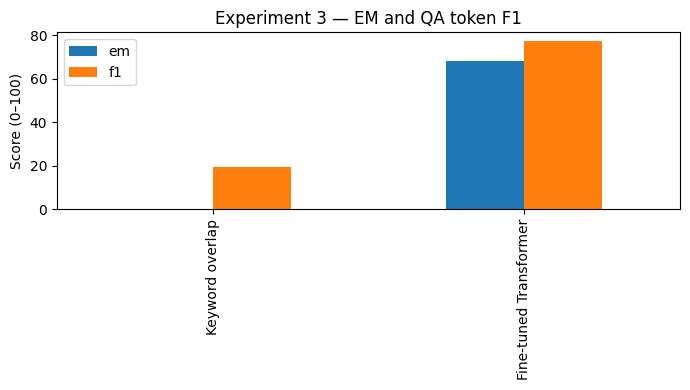

In [11]:
if RUN_TRAINING and trained_runs and 384 in trained_runs:
    base_preds = [keyword_overlap_baseline(row["question"], row["context"]) for row in splits["test"]]
    base_records = [{"id": row["id"], "prediction": pred["answer"]} for row, pred in zip(splits["test"], base_preds)]
    references = [{"id": row["id"], "answers": row["answers"]} for row in splits["test"]]
    baseline_metrics = evaluate_predictions(base_records, references)
    transformer_metrics = trained_runs[384]["metrics"]
    compare = pd.DataFrame([{"model": "Keyword overlap", **baseline_metrics},
                            {"model": "Fine-tuned Transformer", **transformer_metrics}])
    display(compare)
    exp3_rows = [
        {"experiment": "em_vs_f1", "model": "Keyword overlap baseline", "setting": "baseline",
         "split": "held-out SQuAD validation partition", "num_samples": len(splits["test"]),
         "em": baseline_metrics["em"], "f1": baseline_metrics["f1"], "seed": BASE.seed},
        {"experiment": "em_vs_f1", "model": BASE.model_id, "setting": "fine-tuned max_length=384",
         "split": "held-out SQuAD validation partition", "num_samples": len(splits["test"]),
         "max_length": 384, "stride": COMMON_STRIDE, "eval_windows": len(trained_runs[384]["test_features"]),
         "train_answer_coverage": trained_runs[384]["train_answer_coverage"],
         "validation_answer_coverage": trained_runs[384]["validation_answer_coverage"],
         "heldout_answer_coverage": trained_runs[384]["heldout_answer_coverage"],
         "training_steps": trained_runs[384]["training_steps"], "em": transformer_metrics["em"],
         "f1": transformer_metrics["f1"], "training_time_seconds": trained_runs[384]["training_time"], "seed": BASE.seed},
    ]
    result_rows.extend(exp3_rows); save_results(result_rows)
    prediction_records = []
    for row, pred in zip(splits["test"], base_preds):
        prediction_records.append({"experiment": "baseline", "id": row["id"], "question": row["question"],
            "context": row["context"], "gold_answers": json.dumps(row["answers"], ensure_ascii=False), **pred})
    for row, pred in zip(splits["test"], trained_runs[384]["predictions"]):
        prediction_records.append({"experiment": "transformer", "id": row["id"], "question": row["question"],
            "context": row["context"], "gold_answers": json.dumps(row["answers"], ensure_ascii=False), **pred})
    pd.DataFrame(prediction_records).to_csv(RUN_OUTPUT_DIR / "predictions.csv", index=False)
    partial = []
    for row, pred in zip(splits["test"], trained_runs[384]["predictions"]):
        score = score_one_example(pred["prediction"], row["answers"]["text"])
        if score["em"] == 0 and score["f1"] > 0:
            partial.append({"id": row["id"], "question": row["question"],
                            "gold_answers": row["answers"]["text"], "prediction": pred["prediction"], **score})
    partial_df = pd.DataFrame(partial)
    partial_df.to_csv(RUN_OUTPUT_DIR / "em_zero_f1_positive.csv", index=False)
    print("Actual cases with EM=0 and F1>0:", len(partial_df))
    display(partial_df.head(5))
    ax = compare.set_index("model")[["em", "f1"]].plot(kind="bar", figsize=(7, 4))
    ax.set(title="Experiment 3 — EM and QA token F1", ylabel="Score (0–100)", xlabel="")
    plt.tight_layout(); plt.savefig(FORMAL_OUTPUT_DIR / "em_f1_analysis.png", dpi=160); plt.show()
else:
    print("NOT_RUN: Experiment 3 requires a completed 384-token run.")


## Experiment 4 — Question/Context Matching (W10 mục 22)

Groups use a fixed rule before reading model predictions: content-word overlap ratio ≥ 0.5 is high; otherwise low. Report sample counts with scores.


In [12]:
def lexical_overlap(question, context):
    terms = question_content_words(question)
    context_terms = set(re.findall(r"[\w']+", context.lower()))
    return len(terms & context_terms) / len(terms) if terms else 0.0

if RUN_TRAINING and trained_runs and 384 in trained_runs:
    scores = [lexical_overlap(row["question"], row["context"]) for row in splits["test"]]
    groups = [("high_overlap", [i for i, score in enumerate(scores) if score >= 0.5]),
              ("low_overlap", [i for i, score in enumerate(scores) if score < 0.5])]
    rows = []
    for name, ids in groups:
        if ids:
            refs = [{"id": splits["test"][i]["id"], "answers": splits["test"][i]["answers"]} for i in ids]
            preds = [trained_runs[384]["predictions"][i] for i in ids]
            metrics = evaluate_predictions(preds, refs)
        else:
            metrics = {"em": float("nan"), "f1": float("nan")}
        rows.append({"group": name, "threshold": 0.5, "num_samples": len(ids), **metrics})
    matching_table = pd.DataFrame(rows); display(matching_table)
    matching_table.to_csv(RUN_OUTPUT_DIR / "question_context_groups.csv", index=False)
    result_rows.extend([{"experiment": "question_context_matching", "model": BASE.model_id,
        "setting": row["group"], "split": "held-out SQuAD validation partition", "num_samples": row["num_samples"],
        "max_length": 384, "stride": COMMON_STRIDE, "em": row["em"], "f1": row["f1"], "seed": BASE.seed}
        for row in rows])
    save_results(result_rows)
else:
    print("NOT_RUN: lexical matching analysis requires actual held-out predictions.")


,group,threshold,num_samples,em,f1
0,high_overlap,0.5,824,69.296117,78.488621
1,low_overlap,0.5,176,61.931818,72.610461


## Experiment 5 — Answer Length (W10 mục 23)

Phân nhóm theo số subword tokens của gold answer đầu tiên: 1, 2–3, 4–6, 7+.


,answer_length,num_samples,em,f1
0,1,224,68.303571,76.776574
1,2-3,372,70.161290,78.600448
2,4-6,275,72.363636,80.882690
3,7+,129,51.937984,68.015549


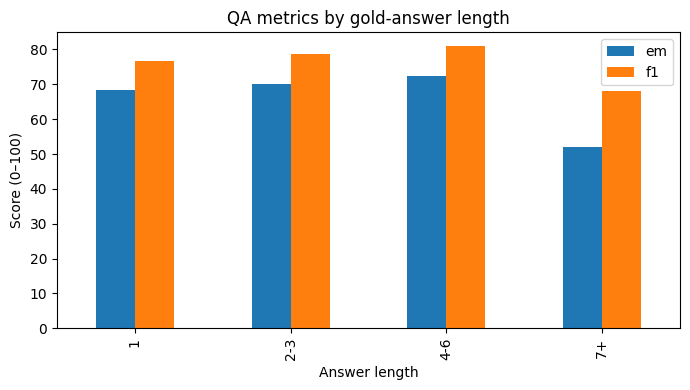

In [13]:
def answer_length_group(text):
    # Quy ước: số subword tokens theo QA tokenizer, không tính special tokens.
    count = len(tokenizer(text, add_special_tokens=False)["input_ids"])
    return "1" if count == 1 else "2-3" if count <= 3 else "4-6" if count <= 6 else "7+"

if RUN_TRAINING and trained_runs and 384 in trained_runs:
    grouped = []; predictions = trained_runs[384]["predictions"]
    for group in ("1", "2-3", "4-6", "7+"):
        ids = [i for i, row in enumerate(splits["test"])
               if row["answers"]["text"] and answer_length_group(row["answers"]["text"][0]) == group]
        refs = [{"id": splits["test"][i]["id"], "answers": splits["test"][i]["answers"]} for i in ids]
        metrics = evaluate_predictions([predictions[i] for i in ids], refs) if ids else {"em": float("nan"), "f1": float("nan")}
        grouped.append({"answer_length": group, "num_samples": len(ids), **metrics})
    length_table = pd.DataFrame(grouped); display(length_table)
    length_table.to_csv(RUN_OUTPUT_DIR / "answer_length_metrics.csv", index=False)
    result_rows.extend([{"experiment": "answer_length", "model": BASE.model_id,
        "setting": row["answer_length"], "split": "held-out SQuAD validation partition",
        "num_samples": row["num_samples"], "max_length": 384, "stride": COMMON_STRIDE,
        "em": row["em"], "f1": row["f1"], "seed": BASE.seed}
        for row in grouped])
    save_results(result_rows)
    ax = length_table.set_index("answer_length")[["em", "f1"]].plot(kind="bar", figsize=(7, 4))
    ax.set(title="QA metrics by gold-answer length", ylabel="Score (0–100)", xlabel="Answer length")
    plt.tight_layout(); plt.savefig(FORMAL_OUTPUT_DIR / "answer_length_analysis.png", dpi=160); plt.show()
else:
    print("NOT_RUN: answer-length analysis requires actual held-out predictions.")


## 10. Learning curves, evidence and errors

Learning curves use actual per-epoch train/validation losses. Error candidate export compares spans in original context character coordinates; student writes the explanations.

,epoch,train_loss,validation_loss,validation_em,validation_f1,max_length
0,1.0,1.524033,1.344869,60.8,71.209150,128
1,2.0,0.727302,1.437850,62.3,72.472679,128
2,1.0,2.208744,1.515358,63.9,73.562708,256
3,2.0,1.099401,1.522393,63.9,74.805864,256
4,1.0,2.301051,1.604867,60.3,70.642905,384
5,2.0,1.147308,1.488373,64.5,75.843500,384


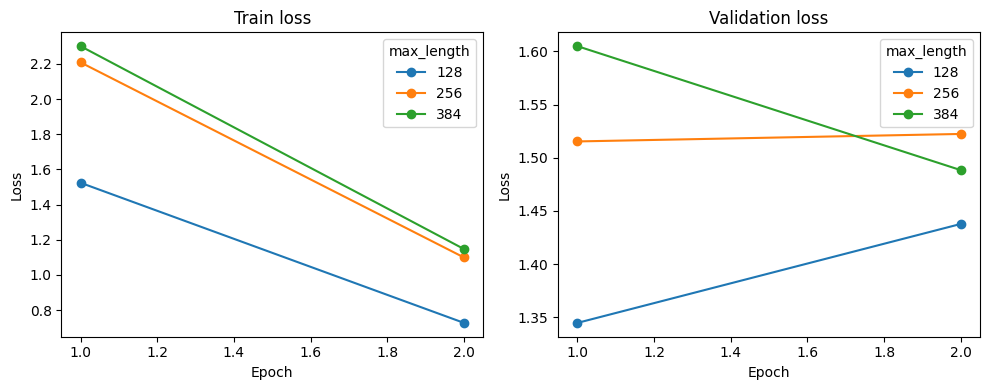

{'wrong_start_count': 278, 'wrong_end_count': 249, 'wrong_span_count': 352}


In [14]:
if history_rows:
    history = pd.DataFrame(history_rows); display(history)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for length, part in history.groupby("max_length"):
        axes[0].plot(part["epoch"], part["train_loss"], marker="o", label=str(length))
        axes[1].plot(part["epoch"], part["validation_loss"], marker="o", label=str(length))
    axes[0].set(title="Train loss", xlabel="Epoch", ylabel="Loss")
    axes[1].set(title="Validation loss", xlabel="Epoch", ylabel="Loss")
    axes[0].legend(title="max_length"); axes[1].legend(title="max_length")
    fig.tight_layout(); fig.savefig(FORMAL_OUTPUT_DIR / "learning_curves.png", dpi=160); plt.show()
else:
    print("NOT_RUN: no real training history; learning_curves.png not created")

if ERROR_ANALYSIS_IMPLEMENTED and RUN_TRAINING and trained_runs and 384 in trained_runs:
    error_rows = []
    for example, prediction in zip(splits["test"], trained_runs[384]["predictions"]):
        gold_texts = example["answers"]["text"]
        gold_starts = example["answers"]["answer_start"]
        score = score_one_example(prediction["prediction"], gold_texts)
        row = {"sample_id": example["id"], "question": example["question"],
            "context": example["context"], "gold_answer": gold_texts[0] if gold_texts else "",
            "prediction": prediction["prediction"], "gold_start_char": gold_starts[0] if gold_starts else None,
            "gold_end_char": (gold_starts[0] + len(gold_texts[0])) if gold_starts and gold_texts else None,
            "predicted_start_char": prediction.get("start_char"), "predicted_end_char": prediction.get("end_char"),
            **score}
        classification = classify_span_errors(example["question"], example["context"], example["answers"], prediction)
        row.update({key: classification[key] for key in ("wrong_start", "wrong_end", "wrong_span", "error_type")})
        error_rows.append(row)
    error_df = pd.DataFrame(error_rows)
    error_df.to_csv(RUN_OUTPUT_DIR / "error_candidates.csv", index=False)
    print({"wrong_start_count": int(error_df["wrong_start"].sum()),
           "wrong_end_count": int(error_df["wrong_end"].sum()),
           "wrong_span_count": int(error_df["wrong_span"].sum())})
else:
    print("NOT_RUN: error evidence export requires verified metric/alignment code and predictions.")


## 11. Prediction 1–4 controlled examples

Sau khi ghi prediction ban đầu: tạo distractor, câu không liên quan, đổi thứ tự câu và answer dài/ngắn. Cập nhật character offsets của context chỉnh sửa bằng code do bạn tự hoàn thiện; tách synthetic examples khỏi kết quả held-out test. Không xem lexical overlap là bằng chứng đủ cho semantic understanding.

## 12. Controlled examples for Prediction 1–4

Điền question/context/answer do bạn tự chọn sau khi ghi prediction ban đầu. Tự xác định answer_start mới cho context đã chỉnh sửa; không đưa các ví dụ synthetic vào test metrics.

In [15]:
# Các controlled cases dùng riêng cho inference, không đưa vào held-out metrics.
# Gold spans chỉ để đối chiếu sau khi model đã dự đoán; không truyền vào hàm inference.
CONTROLLED_CASES = [
    {
        "case": "high lexical-overlap distractor",
        "question": "Who designed the Cedar Bridge?",
        "original_context": "Engineer Maya Chen designed the Cedar Bridge in 2011.",
        "modified_context": "Owen Lee discussed the Cedar Bridge design at a public meeting. Engineer Maya Chen designed the Cedar Bridge in 2011.",
        "original_gold_answer": "Maya Chen", "modified_gold_answer": "Maya Chen",
    },
    {
        "case": "short versus long answer span",
        "question": "What did the team discover?",
        "original_context": "The team discovered a cave.",
        "modified_context": "The team discovered a previously unknown limestone cave beneath the eastern ridge after several days of mapping.",
        "original_gold_answer": "a cave",
        "modified_gold_answer": "a previously unknown limestone cave beneath the eastern ridge",
    },
    {
        "case": "irrelevant information added",
        "question": "Who was the observatory's first director?",
        "original_context": "The observatory opened in 1998. Its first director was Nadia Karim.",
        "modified_context": "Local weather was unusually clear that week. The observatory opened in 1998. A nearby school also held a science fair. Its first director was Nadia Karim.",
        "original_gold_answer": "Nadia Karim", "modified_gold_answer": "Nadia Karim",
    },
    {
        "case": "sentence order changed",
        "question": "Who founded the robotics lab?",
        "original_context": "Mina Patel founded the robotics lab in 2012. The lab later moved to a larger building.",
        "modified_context": "The lab later moved to a larger building. Mina Patel founded the robotics lab in 2012.",
        "original_gold_answer": "Mina Patel", "modified_gold_answer": "Mina Patel",
    },
]

if CONTROLLED_CASES and RUN_TRAINING and PREDICTION_COMPLETED and TOKENIZER_AVAILABLE and ALIGNMENT_IMPLEMENTED and METRICS_IMPLEMENTED and 384 in trained_runs:
    from document_qa import predict_span
    application_model = AutoModelForQuestionAnswering.from_pretrained(trained_runs[384]["checkpoint"]).to(DEVICE)
    controlled_rows = []
    for case in CONTROLLED_CASES:
        for version_name in ("original", "modified"):
            context = case[f"{version_name}_context"]
            gold_answer = case[f"{version_name}_gold_answer"]
            gold_start = context.find(gold_answer)
            if gold_start < 0:
                raise ValueError(f"Gold answer not present in controlled context: {case['case']} / {version_name}")
            result = predict_span(case["question"], context, application_model, tokenizer,
                                  max_length=384, stride=COMMON_STRIDE)
            controlled_rows.append({"case": case["case"], "version": version_name,
                "question": case["question"], "context": context, "gold_answer": gold_answer,
                "gold_start_char": gold_start, "gold_end_char": gold_start + len(gold_answer), **result})
    controlled_df = pd.DataFrame(controlled_rows); display(controlled_df)
    controlled_df.to_csv(RUN_OUTPUT_DIR / "prediction_evidence.csv", index=False)
    del application_model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    print("NOT_RUN: controlled examples require a completed prediction.md, verified student code and 384-token model.")


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

,case,version,question,context,gold_answer,gold_start_char,gold_end_char,id,prediction,start_char,end_char
0,high lexical-overlap distractor,original,Who designed the Cedar Bridge?,Engineer Maya Chen designed the Cedar Bridge i...,Maya Chen,9,18,application-input,Maya Chen,9,18
1,high lexical-overlap distractor,modified,Who designed the Cedar Bridge?,Owen Lee discussed the Cedar Bridge design at ...,Maya Chen,73,82,application-input,Maya Chen,73,82
2,short versus long answer span,original,What did the team discover?,The team discovered a cave.,a cave,20,26,application-input,a cave,20,26
3,short versus long answer span,modified,What did the team discover?,The team discovered a previously unknown limes...,a previously unknown limestone cave beneath th...,20,81,application-input,limestone cave,41,55
4,irrelevant information added,original,Who was the observatory's first director?,The observatory opened in 1998. Its first dire...,Nadia Karim,55,66,application-input,Nadia Karim,55,66
5,irrelevant information added,modified,Who was the observatory's first director?,Local weather was unusually clear that week. T...,Nadia Karim,142,153,application-input,Nadia Karim,142,153
6,sentence order changed,original,Who founded the robotics lab?,Mina Patel founded the robotics lab in 2012. T...,Mina Patel,0,10,application-input,Mina Patel,0,10
7,sentence order changed,modified,Who founded the robotics lab?,The lab later moved to a larger building. Mina...,Mina Patel,42,52,application-input,Mina Patel,42,52


## 13. Tùy chọn đồng bộ artifacts lên Google Drive

Chỉ sao chép files đã tồn tại sau khi chạy. Hãy mount Drive trong Colab và bật `EXPORT_TO_DRIVE=True` ở cell cấu hình.

In [16]:
if EXPORT_TO_DRIVE:
    from shutil import copy2
    DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    files_to_copy = [RESULTS_PATH, FORMAL_OUTPUT_DIR / "learning_curves.png",
                     FORMAL_OUTPUT_DIR / "em_f1_analysis.png", FORMAL_OUTPUT_DIR / "answer_length_analysis.png"]
    for source in files_to_copy:
        if source.is_file():
            copy2(source, DRIVE_OUTPUT_DIR / source.name)
    if (LAB_DIR / "outputs").is_dir():
        import shutil
        shutil.copytree(LAB_DIR / "outputs", DRIVE_OUTPUT_DIR / "outputs", dirs_exist_ok=True)
    print("Copied existing artifacts to:", DRIVE_OUTPUT_DIR)
else:
    print("Drive export disabled; artifacts remain in Lab10/.")


Drive export disabled; artifacts remain in Lab10/.


## 14. Kiểm tra deliverables và đóng gói kết quả\n\nCell này chỉ đóng ZIP khi results.csv và ba biểu đồ thực nghiệm tồn tại, hợp lệ. ZIP không chứa model weights hoặc dataset cache. Có thể bật tải xuống hoặc lưu Drive sau khi kiểm tra.

In [17]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import csv

required_files = [
    "README.md", "calculations.md", "prediction.md", "tokenizer_alignment.ipynb",
    "qa_model.py", "qa_finetuning.ipynb", "results.csv", "learning_curves.png",
    "em_f1_analysis.png", "answer_length_analysis.png", "error_analysis.md",
    "document_qa.py", "reflection.md", "calculations.pdf", "prediction.pdf",
    "requirements.txt", "student_implementation_guide.md",
]
missing_files = [name for name in required_files if not (LAB_DIR / name).is_file()]
print("Missing deliverables:", missing_files if missing_files else "none")

results_path = LAB_DIR / "results.csv"
result_rows_check = []
if results_path.is_file():
    with results_path.open(newline="", encoding="utf-8") as stream:
        result_rows_check = list(csv.DictReader(stream))
print("results.csv rows:", len(result_rows_check))

png_files = ["learning_curves.png", "em_f1_analysis.png", "answer_length_analysis.png"]
png_status = {}
for name in png_files:
    path = LAB_DIR / name
    try:
        from PIL import Image
        with Image.open(path) as image:
            image.verify()
        png_status[name] = "valid"
    except Exception as error:
        png_status[name] = f"missing/invalid: {error}"
print("PNG status:", png_status)

if result_rows_check:
    result_summary = pd.DataFrame(result_rows_check)
    display(result_summary.groupby("experiment", dropna=False).size().rename("rows").to_frame())
else:
    print("NOT_RUN: no experiment result rows to summarize")

required_experiment_outputs_exist = (
    not missing_files and bool(result_rows_check)
    and all(png_status[name] == "valid" for name in png_files)
)
if required_experiment_outputs_exist:
    zip_path = LAB_DIR / "Lab10_results.zip"
    package_candidates = [LAB_DIR / name for name in required_files]
    package_candidates += [
        RUN_OUTPUT_DIR / "predictions.csv",
        RUN_OUTPUT_DIR / "error_candidates.csv",
        RUN_OUTPUT_DIR / "training_history.csv",
        RUN_OUTPUT_DIR / "run_config.json",
        RUN_OUTPUT_DIR / "prediction_evidence.csv",
    ]
    excluded_parts = {"checkpoints", "dataset_cache", ".venv", "venv"}
    with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
        for path in package_candidates:
            if path.is_file() and not (excluded_parts & set(path.parts)):
                archive.write(path, path.relative_to(LAB_DIR))
    print("Created result archive:", zip_path)

    DOWNLOAD_RESULTS_ZIP = False
    SAVE_RESULTS_ZIP_TO_DRIVE = False
    if SAVE_RESULTS_ZIP_TO_DRIVE:
        drive_path = Path("/content/drive/MyDrive/NLP/Lab10_results.zip")
        drive_path.parent.mkdir(parents=True, exist_ok=True)
        import shutil
        shutil.copy2(zip_path, drive_path)
        print("Saved to Drive:", drive_path)
    if DOWNLOAD_RESULTS_ZIP:
        from google.colab import files
        files.download(str(zip_path))
else:
    print("NOT_RUN: ZIP not created; real result CSV and all three valid PNGs are required.")


Missing deliverables: none
results.csv rows: 12
PNG status: {'learning_curves.png': 'valid', 'em_f1_analysis.png': 'valid', 'answer_length_analysis.png': 'valid'}


,rows
experiment,
answer_length,4
context_length,3
em_vs_f1,2
pretrained_qa,1
question_context_matching,2


Created result archive: /content/NLP/Lab10/Lab10_results.zip
